# AI-Powered Inventory Intelligence and Reorder Point Optimization
### AI in Operations | Session II: AI Applications in Reorder Point and Inventory Management
**Student:** Atharva Soundankar | **Roll number:** as25dxb020 | **Programme:** MAIB | **Batch:** September 2025
**Institution:** SP Jain School of Global Management

## Objective
Enhance a reorder-point calculator with predictive intelligence, in three steps: (1) forecast demand with machine learning, (2) compute dynamic safety stock with a probabilistic formula and Monte Carlo simulation, (3) replace manual parameter sweeps with Bayesian optimization of the reorder point under a service constraint.

## Dataset
The data is **synthetic**, not observed business data. It is 104 weeks of demand for one SKU (`SKU-A101`) generated with a fixed seed (42): trend, annual seasonality, random promotions and noise. Lead time, costs and service targets are **assumptions**. All calculations live in `inventory.py`, shared with the Streamlit dashboard (`app.py`), so the notebook and dashboard always agree. Units: demand per week, lead time in weeks.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import inventory as inv
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
df = inv.validate(inv.make_synthetic())
print(df.shape)
df.head()

(104, 4)


,week,sku,demand,promo
0,2024-11-11,SKU-A101,125,0
1,2024-11-18,SKU-A101,109,0
2,2024-11-25,SKU-A101,94,0
3,2024-12-02,SKU-A101,118,0
4,2024-12-09,SKU-A101,138,1


## 1. Demand forecasting
Chronological split: the last 12 weeks are held out. A 4-week moving average is the baseline; two linear regressions (trend + promo, and the same plus annual sine/cosine seasonality) are the ML models. Accuracy is MAE and WAPE (sum of absolute errors divided by sum of actual demand). New data can be appended to the CSV and the whole pipeline refits.

                                          name   mae  wape
              4-week moving average (baseline) 18.92 14.19
              Linear regression: trend + promo 16.59 12.44
Linear regression: trend + promo + seasonality 12.53  9.39
Best model: Linear regression: trend + promo + seasonality | holdout RMSE (sigma_D): 14.95 | mean forecast: 141.8


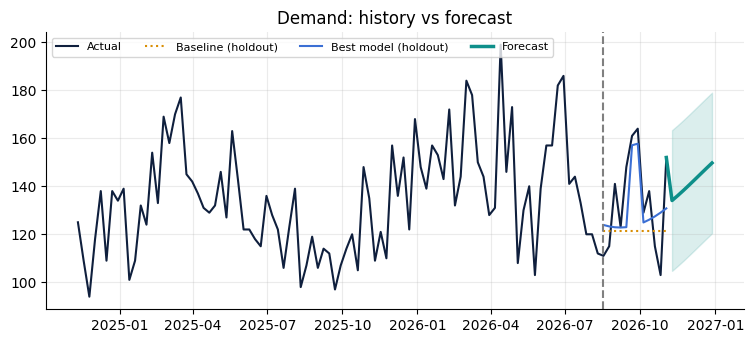

In [2]:
F = inv.forecast(df, horizon=8)
print(pd.DataFrame(F["models"]).round(2).to_string(index=False))
print("Best model:", F["best"], "| holdout RMSE (sigma_D):", round(F["sigma"], 2), "| mean forecast:", round(F["mean_forecast"], 1))
s = pd.DataFrame(F["series"])
s["week"] = pd.to_datetime(s["week"])
fig, ax = plt.subplots()
ax.plot(s.week, s.actual, color="#0f1f3d", label="Actual")
ax.plot(s.week, s.baseline, ":", color="#d98e04", label="Baseline (holdout)")
ax.plot(s.week, s.model, color="#3b6fd4", label="Best model (holdout)")
ax.plot(s.week, s.forecast, color="#0e8f8a", lw=2.5, label="Forecast")
f = s.dropna(subset=["band"])
ax.fill_between(f.week, [b[0] for b in f.band], [b[1] for b in f.band], color="#0e8f8a", alpha=.15)
ax.axvline(pd.to_datetime(F["split_week"]), color="grey", ls="--")
ax.set_title("Demand: history vs forecast")
ax.legend(ncol=4, fontsize=8)
plt.show()

**Interpretation.** The seasonal regression beats the moving average on the held-out weeks because the series has a real trend and annual cycle that a flat average cannot follow. Its holdout RMSE becomes the demand standard deviation for the next step, so forecast uncertainty flows into the buffer.

## 2. Dynamic safety stock and Monte Carlo
$$SS = Z\sqrt{\sigma_D^2 L + \bar D^2 \sigma_L^2},\qquad ROP = \bar D L + SS$$
Z is the normal quantile of the target cycle service level, $\bar D$ mean weekly demand, $\sigma_D$ its standard deviation, L mean lead time and $\sigma_L$ lead-time standard deviation. Assumptions: normal, independent demand and lead time. Monte Carlo (2,000 runs, seed 42) draws a lead time and then lead-time demand directly, with no normality shortcut on their product.

Z=1.6449  SS=121.7  ROP=405.2
                                              name    mean     p50     p95  stockout  mc_rop  formula_rop
                                          Baseline 279.953 280.962 407.481     0.052 407.481      405.180
Supplier delay (+1 week, 2x lead-time variability) 417.957 421.130 662.852     0.544 662.852      662.305
      Demand spike (+30% demand, 1.5x variability) 364.008 364.468 531.530     0.324 531.530      528.862
Reproducible with fixed seed: True


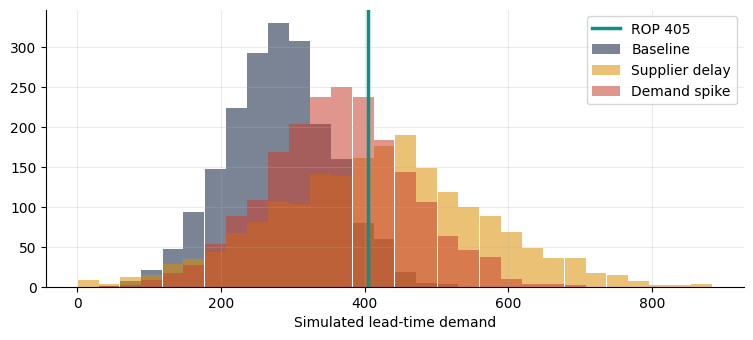

In [3]:
d, sd, L, sL, service = F["mean_forecast"], F["sigma"], 2.0, 0.5, 0.95
ss = inv.safety_stock(d, sd, L, sL, service)
manual = ss["z"] * np.sqrt(sd**2 * L + d**2 * sL**2)
assert abs(manual - ss["ss"]) < 1e-9 and abs(d * L + manual - ss["rop"]) < 1e-9
print(f"Z={ss['z']:.4f}  SS={ss['ss']:.1f}  ROP={ss['rop']:.1f}")
R = inv.risk_scenarios(d, sd, L, sL, service, n=2000)
print(pd.DataFrame([{k: v for k, v in r.items() if k != "counts"} for r in R["scenarios"]]).round(3).to_string(index=False))
print("Reproducible with fixed seed:", np.array_equal(inv.simulate_ltd(d, sd, L, sL), inv.simulate_ltd(d, sd, L, sL)))
fig, ax = plt.subplots()
w = R["bins"][1] - R["bins"][0]
for r, c in zip(R["scenarios"], ["#0f1f3d", "#d98e04", "#c8402f"]):
    ax.bar(R["bins"], r["counts"], width=w, alpha=.55, color=c, label=r["name"].split(" (")[0])
ax.axvline(R["rop"], color="#0e8f8a", lw=2.5, label=f"ROP {R['rop']:.0f}")
ax.set_xlabel("Simulated lead-time demand")
ax.legend()
plt.show()

**Interpretation.** In the baseline scenario the simulated stockout rate sits close to the 5% target, so the formula is trustworthy when its assumptions hold. Under a supplier delay or a demand spike the same ROP stocks out far more often, which shows why a static buffer is risky and why it should be recomputed when lead time or demand behaviour changes.

## 3. Bayesian optimization of the reorder point
Optuna's TPE sampler (sequential, model-based) searches the integer ROP for 40 trials. Objective, per year: **ordering cost + holding cost + expected shortage cost**, with order quantity fixed at the EOQ. Constraint: **cycle service level at least 95%**, passed to Optuna as a trial constraint so infeasible regions are avoided. Costs (unit 20, holding 25% per year, order 100, shortage 15 per unit) are hypothetical.

Best feasible ROP 430 | cost 3582 | service 97.5%
Analytical ROP 405 | cost 3655 | service 94.8%   (EOQ = 543)
Feasible trials: 26 of 40


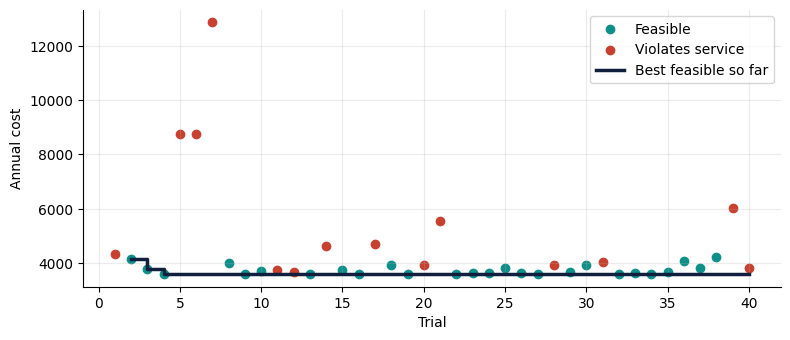

In [4]:
O = inv.optimize_rop(d, sd, L, sL, service, n_trials=40)
b, bl = O["best"], O["baseline"]
print(f"Best feasible ROP {b['rop']} | cost {b['cost']:.0f} | service {b['service']:.1%}")
print(f"Analytical ROP {bl['rop']:.0f} | cost {bl['cost']:.0f} | service {bl['service']:.1%}   (EOQ = {O['q']:.0f})")
assert b["service"] >= service
t = pd.DataFrame(O["trials"])
print("Feasible trials:", int(t.feasible.sum()), "of", len(t))
fig, ax = plt.subplots()
ax.scatter(t.trial[t.feasible], t.cost[t.feasible], c="#0e8f8a", label="Feasible")
ax.scatter(t.trial[~t.feasible], t.cost[~t.feasible], c="#c8402f", label="Violates service")
ax.step(t.trial, t.best, where="post", color="#0f1f3d", lw=2.5, label="Best feasible so far")
ax.set_xlabel("Trial")
ax.set_ylabel("Annual cost")
ax.legend()
plt.show()

**Interpretation.** The optimizer finds the cheapest ROP that still meets the service constraint. Compare it with the analytical ROP: the formula's simulated service lands just under the 95% target, so the optimizer raises the ROP slightly. The extra holding cost is more than repaid by fewer expected shortages, so total cost falls as well.

## 4. Adaptive intelligence: what happens when customer demand changes?
The slides ask for predictive intelligence, adaptive decision-making and real-time optimization. The last 26 weeks are **replayed week by week**: each week the seasonal regression is refitted (recent weeks weigh more, 0.95 per week), $\sigma_D$ is re-estimated from the last 12 one-step forecast errors, and SS and ROP are recomputed. A **static** ROP, fixed before the replay, is the comparison. A *miss* means the demand during lead time exceeded the ROP held that week. A +40% demand change is injected into the final 10 weeks.

                  Scenario  Static ROP misses  Adaptive ROP misses  Avg adaptive ROP  Static ROP  Latest sigma_D
                 No change                  0                    0               383         430            19.0
+40% demand, last 10 weeks                  2                    1               420         430            42.3


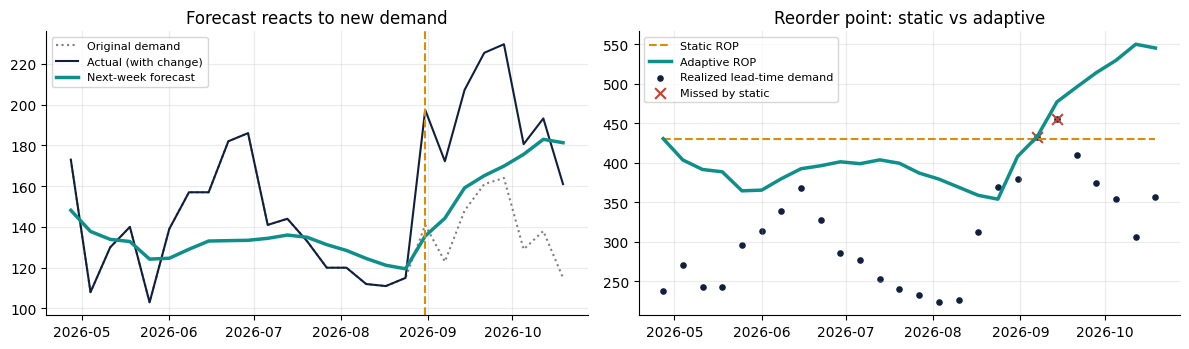

In [5]:
P0 = inv.adaptive_replay(df, L, sL, service, shock_pct=0.0)
P1 = inv.adaptive_replay(df, L, sL, service, shock_pct=0.4, shock_weeks=10)
summary = pd.DataFrame({
    "Scenario": ["No change", "+40% demand, last 10 weeks"],
    "Static ROP misses": [P0["misses_static"], P1["misses_static"]],
    "Adaptive ROP misses": [P0["misses_adaptive"], P1["misses_adaptive"]],
    "Avg adaptive ROP": [round(P0["avg_rop_adaptive"]), round(P1["avg_rop_adaptive"])],
    "Static ROP": [round(P0["avg_rop_static"]), round(P1["avg_rop_static"])],
    "Latest sigma_D": [round(P0["latest"]["sd"], 1), round(P1["latest"]["sd"], 1)]})
print(summary.to_string(index=False))
r = pd.DataFrame(P1["rows"]); r["week"] = pd.to_datetime(r["week"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(r.week, r.original, ":", color="grey", label="Original demand"); ax[0].plot(r.week, r.actual, color="#0f1f3d", label="Actual (with change)")
ax[0].plot(r.week, r.forecast_next, color="#0e8f8a", lw=2.5, label="Next-week forecast"); ax[0].axvline(pd.to_datetime(P1["shock_week"]), color="#d98e04", ls="--")
ax[0].set_title("Forecast reacts to new demand"); ax[0].legend(fontsize=8)
ax[1].plot(r.week, r.rop_static, "--", color="#d98e04", label="Static ROP"); ax[1].plot(r.week, r.rop_adaptive, color="#0e8f8a", lw=2.5, label="Adaptive ROP")
ax[1].scatter(r.week, r.realized_ltd, color="#0f1f3d", s=14, label="Realized lead-time demand")
m = r[r.miss_static]; ax[1].scatter(m.week, m.realized_ltd, color="#c8402f", marker="x", s=60, label="Missed by static")
ax[1].set_title("Reorder point: static vs adaptive"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** With no change, the adaptive policy holds a lower ROP than the static one and still has no misses, so it saves inventory. When demand jumps, the static ROP is blind and misses lead-time demand, while the adaptive ROP rises within a few weeks because both the forecast and the re-estimated $\sigma_D$ increase. **Real-time optimization:** the latest forecast and $\sigma_D$ are passed straight back into the Optuna optimizer, so the reorder point is re-optimized as soon as new data arrives.

In [6]:
lat = P1["latest"]
O2 = inv.optimize_rop(lat["d"], lat["sd"], L, sL, service, n_trials=25)
print(f"After the demand change: forecast {lat['d']:.0f}/week, sigma_D {lat['sd']:.1f}")
print(f"Formula ROP {lat['rop']:.0f} | re-optimized (Optuna, 25 trials) ROP {O2['best']['rop']} at {O2['best']['service']:.1%} service, cost {O2['best']['cost']:.0f}")

After the demand change: forecast 183/week, sigma_D 42.3
Formula ROP 545 | re-optimized (Optuna, 25 trials) ROP 597 at 97.9% service, cost 4429


## 5. AI-driven sensitivity analysis
Instead of a manual sweep over a grid, Optuna's TPE sampler **searches the uncertainty box** for the combination of inputs that hurts a fixed ROP the most (maximum simulated stockout probability), then Optuna's parameter-importance analysis ranks the inputs. Ranges: demand 0.8x to 1.4x, demand variability 0.7x to 2.0x, lead time 0.75x to 1.5x, lead-time variability 0.5x to 2.5x.

Tested ROP 405 | nominal stockout 4.6% | worst case found 96.6%
ROP needed in the worst case to hold 95%: 710
Worst-case inputs: {'demand_mult': 1.35, 'variability_mult': 1.93, 'lead_time_mult': 1.5, 'lead_time_var_mult': 0.71}
Importance: {'demand_mult': 0.46, 'lead_time_var_mult': 0.31, 'lead_time_mult': 0.2, 'variability_mult': 0.03}
A 5-level grid would need 625 simulations; Bayesian search used 60.


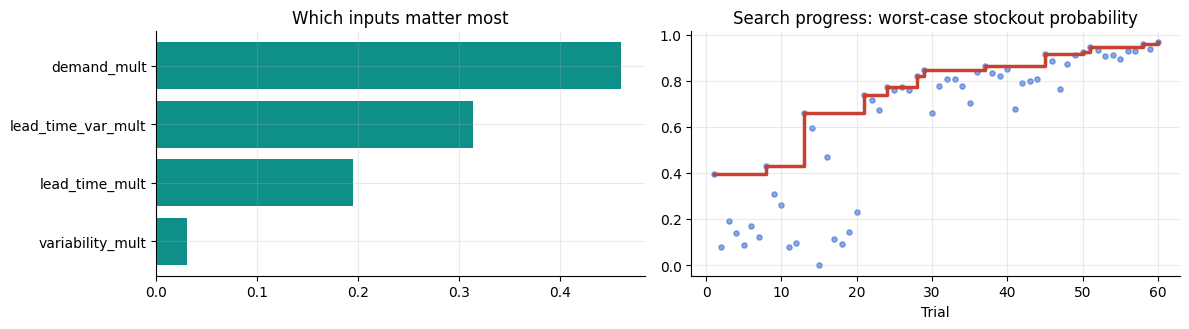

In [7]:
S = inv.ai_sensitivity(d, sd, L, sL, service, rop=ss["rop"], n_trials=60)
print(f"Tested ROP {S['rop']:.0f} | nominal stockout {S['nominal']:.1%} | worst case found {S['worst']['stockout']:.1%}")
print(f"ROP needed in the worst case to hold {service:.0%}: {S['worst']['rop_needed']:.0f}")
print("Worst-case inputs:", {k: round(v, 2) for k, v in S["worst"].items() if k.endswith("mult")})
print("Importance:", {k: round(v, 2) for k, v in S["importance"].items()})
print(f"A 5-level grid would need {S['grid_cost']} simulations; Bayesian search used {S['n_trials']}.")
imp = pd.Series(S["importance"]).sort_values(); t = pd.DataFrame(S["trials"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].barh(imp.index, imp.values, color="#0e8f8a"); ax[0].set_title("Which inputs matter most")
ax[1].scatter(t.trial, t.stockout, s=14, color="#3b6fd4", alpha=.6); ax[1].step(t.trial, t.best, where="post", color="#c8402f", lw=2.5)
ax[1].set_title("Search progress: worst-case stockout probability"); ax[1].set_xlabel("Trial")
plt.tight_layout(); plt.show()

**Interpretation.** The nominal stockout risk is near the 5% target, but the search finds input combinations that push it far higher, which shows how fragile a single point ROP is. The importance chart tells the planner where to spend effort: the top-ranked input (for example demand level or lead time) is the one to monitor or negotiate first. Importance holds inside the tested ranges only.

## 6. Before AI vs With AI
Same data, same 26-week backtest, same +40% demand change in the last 10 weeks. **Before AI** is the classic calculator: average and raw standard deviation of all history, $ROP = \bar D L + Z\sigma\sqrt{L}$, set once, ignoring lead-time variability and trend. **With AI** is the system built above (ML forecast, re-estimated risk, adaptive ROP, Bayesian optimization). Before AI is a modelled baseline, not a real company record.

                         Metric Before AI                             With AI
                  Reorder point       321 420 avg (latest 545, optimized 597)
          Weeks covered (of 26)        15                                  25
         Units short (26 weeks)       638                                  16
Next-week forecast error (WAPE)     20.2%                               18.4%
           Expected annual cost     18540                                4429
         Service level in model       36%                                 98%


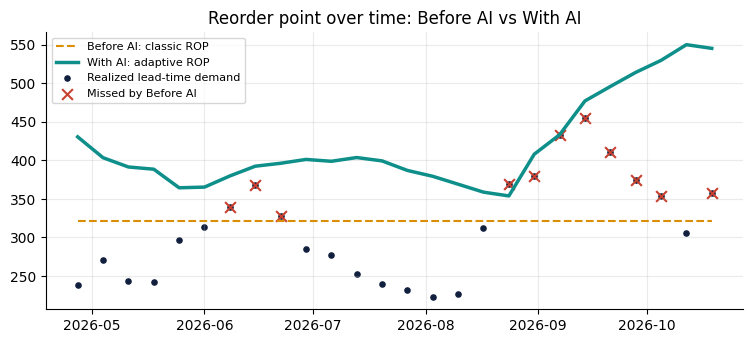

In [8]:
P = inv.adaptive_replay(df, L, sL, service, shock_pct=0.4, shock_weeks=10)
lat = P["latest"]
O2 = inv.optimize_rop(lat["d"], lat["sd"], L, sL, service, n_trials=25)
before = inv.policy_eval(P["rop_classic"], lat["d"], lat["sd"], L, sL)
cmp = pd.DataFrame({
    "Metric": ["Reorder point", "Weeks covered (of 26)", "Units short (26 weeks)", "Next-week forecast error (WAPE)", "Expected annual cost", "Service level in model"],
    "Before AI": [round(P["rop_classic"]), P["weeks"] - P["misses_classic"], round(P["short_classic"]), f"{P['wape_avg']:.1f}%", round(before["cost"]), f"{before['service']:.0%}"],
    "With AI": [f"{P['avg_rop_adaptive']:.0f} avg (latest {lat['rop']:.0f}, optimized {O2['best']['rop']})", P["weeks"] - P["misses_adaptive"], round(P["short_adaptive"]), f"{P['wape_ai']:.1f}%", round(O2["best"]["cost"]), f"{O2['best']['service']:.0%}"]})
print(cmp.to_string(index=False))
r = pd.DataFrame(P["rows"]); r["week"] = pd.to_datetime(r["week"])
fig, ax = plt.subplots()
ax.plot(r.week, r.rop_classic, "--", color="#d98e04", label="Before AI: classic ROP"); ax.plot(r.week, r.rop_adaptive, color="#0e8f8a", lw=2.5, label="With AI: adaptive ROP")
ax.scatter(r.week, r.realized_ltd, s=14, color="#0f1f3d", label="Realized lead-time demand")
m = r[r.miss_classic]; ax.scatter(m.week, m.realized_ltd, color="#c8402f", marker="x", s=60, label="Missed by Before AI")
ax.set_title("Reorder point over time: Before AI vs With AI"); ax.legend(fontsize=8); plt.show()

**Interpretation.** The classic ROP stays flat and keeps missing once demand rises, with far more units short and a much higher expected cost under the new demand level. The AI policy holds more reorder point on average, which is the price of protecting service. When demand is stable, a plain average forecasts about as well as the model (see the sidebar slider in the dashboard); the AI advantage comes from noticing and adapting to change.

## 7. Autopilot: automation on top of the models
A rule-based decision agent turns the model outputs into a weekly action. It compares the inventory position (on hand plus on order) with the latest adaptive ROP, orders whole EOQ batches until the position clears the ROP, and monitors the standardized forecast error for drift (4-week average beyond 1.5 standard deviations) and anomalies (single weeks beyond 2.5). A drift alert or a ROP move above 20% triggers re-optimization.

Action: REORDER 616 units
Position 450 vs ROP 545 (was 430) | cover 2.5 weeks | re-optimization triggered: True
[red] Demand drift upward: over the last 12 weeks, demand ran 2.0 standard deviations above forecast for 4 weeks in a row. ROP moved +27% and the optimizer re-ran automatically.
[amber] 1 demand anomaly week(s) beyond 2.5 standard deviations: 2026-08-31.
[red] Supplier-delay risk: a one-week delay would raise stockout probability to 54%. Consider a backup supplier or a higher buffer.


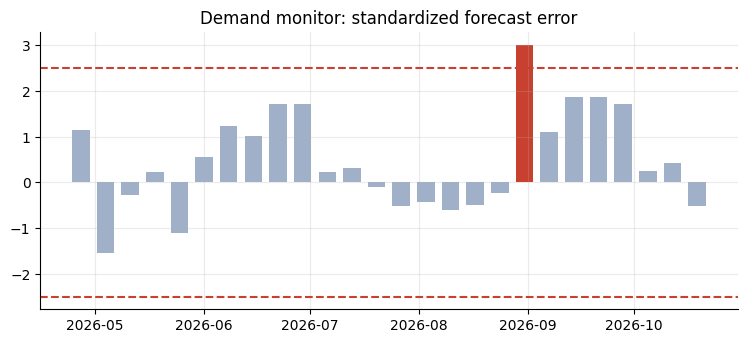

With stable demand: HOLD | Demand is tracking the forecast. No drift detected.


In [9]:
ap = inv.autopilot(P, on_hand=450, on_order=0, q=O2["q"], delay_risk=R["scenarios"][1]["stockout"], service=service)
print("Action:", f"REORDER {ap['qty']} units" if ap["reorder"] else "HOLD")
print(f"Position {ap['position']:.0f} vs ROP {ap['rop']:.0f} (was {ap['rop_before']:.0f}) | cover {ap['cover_weeks']:.1f} weeks | re-optimization triggered: {ap['retrain']}")
for level, text in ap["alerts"]: print(f"[{level}] {text}")
fig, ax = plt.subplots()
ax.bar(r.week, [x["z"] for x in P["rows"]], width=5, color=["#c8402f" if abs(x["z"]) > 2.5 else "#9fb0c8" for x in P["rows"]])
ax.axhline(2.5, color="#c8402f", ls="--"); ax.axhline(-2.5, color="#c8402f", ls="--"); ax.set_title("Demand monitor: standardized forecast error"); plt.show()
stable = inv.autopilot(inv.adaptive_replay(df, L, sL, service), 450, 0, O2["q"], service=service)
print("With stable demand:", "REORDER" if stable["reorder"] else "HOLD", "|", stable["alerts"][0][1])

**Interpretation.** With the demand change the agent recommends an order and flags the drift; with stable demand it holds and reports no drift. This turns forecasting, risk and optimization into a decision that can run every week without manual recalculation.

**Where intelligence could be extended next:** a lead-time prediction model trained on supplier delivery records, multi-SKU forecasting with shared promotion effects, automatic supplier-risk scoring, and an LLM layer that explains the weekly decision in plain language. These need real operational data, so they are noted here rather than simulated.

## Limitations
- Demand is synthetic and covers one SKU; real data needs the same schema (week, demand, optional promo).
- Lead time, costs and service level are assumptions. The result is optimal for this model only, not for a real company.
- The adaptive replay uses one model family (recency-weighted regression) and integer-week lead times; the demand change is injected, not observed.
- Normal approximations for demand and lead time; no demand correlation and no order-quantity optimization beyond EOQ.

## Conclusion
Machine-learning forecasts feed a probabilistic safety-stock formula; Monte Carlo tests it under delay and demand-spike risks; Bayesian optimization then chooses a reorder point against a cost objective and a service constraint, replacing a manual sweep. The Before AI baseline shows what the AI adds, and the Autopilot turns the results into a weekly action. The adaptive replay shows the whole loop reacting to a demand change (refit, new sigma, new ROP, re-optimization), and Bayesian stress-testing ranks which inputs the decision is most sensitive to. The Streamlit dashboard (`streamlit run app.py`) exposes all three steps interactively.